In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

In [2]:
''' FOR KAGGLE NOTEBOOK '''
#  Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

''' FOR JUPYTER NOTEBOOK '''
import kagglehub
path = kagglehub.competition_download('ieee-fraud-detection')

print("Path to competition files:", path)

import os
for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        print(os.path.join(dirname, filename))

Path to competition files: /Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/test_transaction.csv
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/train_identity.csv
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/test_identity.csv
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/sample_submission.csv
/Users/eric/.cache/kagglehub/competitions/ieee-fraud-detection/train_transaction.csv


In [3]:
train_id = pd.read_csv(f'{path}/train_identity.csv')
train_tr = pd.read_csv(f'{path}/train_transaction.csv')
test_id = pd.read_csv(f'{path}/test_identity.csv')
test_tr = pd.read_csv(f'{path}/test_transaction.csv')
sub = pd.read_csv(f'{path}/sample_submission.csv')

In [4]:
print("Number of training samples:", len(train_tr))
print(f"Proportion of fraudulent samples: {train_tr['isFraud'].mean():.4f}")

Number of training samples: 590540
Proportion of fraudulent samples: 0.0350


In [5]:
train_tr.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
train_id.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [7]:
# fix labeling inconsistency in test id columns
test_id.rename(columns=dict([(f'id-{n:02d}', f'id_{n:02d}') for n in range(1, 39)]), inplace=True)

# merge id and transaction data
def merge_tr_id_data(df_tr, df_id):
    df_tr = df_tr.set_index('TransactionID', drop=True)
    df_id = df_id.set_index('TransactionID', drop=True)
    df = df_tr.join(df_id, how='left')
    df['has_identity'] = df['id_01'].notna()
    return df

train = merge_tr_id_data(train_tr, train_id)
test = merge_tr_id_data(test_tr, test_id)

/var/folders/lj/t04__dh55j30m9rhb9f2tbbc0000gn/T/ipykernel_11759/3741117975.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['has_identity'] = df['id_01'].notna()


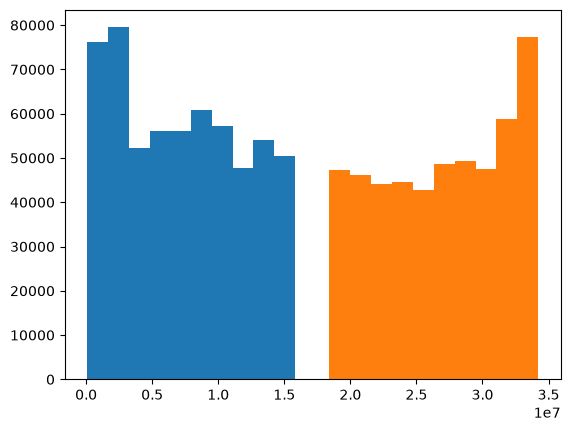

In [8]:
plt.hist(train['TransactionDT'])
plt.hist(test['TransactionDT'])
plt.show()

Given the transaction date ranges are disjoint for the train and test sets, it makes sense to split by date for training and validation.

In [9]:
# split into training and validation sets
N_valid = int(0.2 * len(train))
validation = train.iloc[(-N_valid):]
train = train.iloc[:(-N_valid)]

# Exploring Categorical Variables

In [10]:
# Cardinalities for categorical features
categories_tr = ['ProductCD', 'addr1', 'addr2', 'P_emaildomain', 'R_emaildomain'] 
categories_tr += [f'card{n}' for n in range(1, 7)] + [f'M{n}' for n in range(1,10)]
categories_id = ['DeviceType', 'DeviceInfo'] + [f'id_{n}' for n in range(12,39)] + ['has_identity']
categories = categories_tr + categories_id
num_values = train[categories].nunique()

for cat in categories:
    print(cat, num_values[cat], [str(val) for val in train[cat].unique()[:5]])

ProductCD 5 ['W', 'H', 'C', 'S', 'R']
addr1 328 ['315.0', '325.0', '330.0', '476.0', '420.0']
addr2 70 ['87.0', 'nan', '96.0', '35.0', '60.0']
P_emaildomain 59 ['nan', 'gmail.com', 'outlook.com', 'yahoo.com', 'mail.com']
R_emaildomain 60 ['nan', 'gmail.com', 'hotmail.com', 'outlook.com', 'anonymous.com']
card1 12730 ['13926', '2755', '4663', '18132', '4497']
card2 500 ['nan', '404.0', '490.0', '567.0', '514.0']
card3 106 ['150.0', '117.0', '185.0', '143.0', '144.0']
card4 4 ['discover', 'mastercard', 'visa', 'american express', 'nan']
card5 113 ['142.0', '102.0', '166.0', '117.0', '226.0']
card6 4 ['credit', 'debit', 'nan', 'debit or credit', 'charge card']
M1 2 ['T', 'nan', 'F']
M2 2 ['T', 'nan', 'F']
M3 2 ['T', 'nan', 'F']
M4 3 ['M2', 'M0', 'nan', 'M1']
M5 2 ['F', 'T', 'nan']
M6 2 ['T', 'F', 'nan']
M7 2 ['nan', 'F', 'T']
M8 2 ['nan', 'F', 'T']
M9 2 ['nan', 'F', 'T']
DeviceType 2 ['nan', 'mobile', 'desktop']
DeviceInfo 1639 ['nan', 'SAMSUNG SM-G892A Build/NRD90M', 'iOS Device', 'Windo

In [11]:
train['id_01'].value_counts(dropna=False, normalize=True)

id_01
 NaN     0.745013
-5.0     0.146222
 0.0     0.037737
-20.0    0.019374
-10.0    0.016707
           ...   
-32.0    0.000002
-52.0    0.000002
-43.0    0.000002
-86.0    0.000002
-47.0    0.000002
Name: proportion, Length: 72, dtype: float64

# Feature construction

To capture seasonality effects, we can construct hour / day / weekday columns from TransactionDT.

In [12]:
def populate_datetime_columns(df):
    df = df.copy()
    df.rename(columns={'TransactionDT': 'ts'}, inplace=True)
    df['TransactionDT'] = pd.to_datetime(df['ts'], unit='s')
    df['day'] = df['TransactionDT'].dt.day
    df['weekday'] = df['TransactionDT'].dt.dayofweek
    df['hour'] = df['TransactionDT'].dt.hour
    return df

populate_datetime_columns(train)[['TransactionDT', 'day', 'weekday', 'hour']].head()

,TransactionDT,day,weekday,hour
TransactionID,,,,
2987000,1970-01-02 00:00:00,2,4,0
2987001,1970-01-02 00:00:01,2,4,0
2987002,1970-01-02 00:01:09,2,4,0
2987003,1970-01-02 00:01:39,2,4,0
2987004,1970-01-02 00:01:46,2,4,0


## Aggregations by consumer

Many of the features serve as identification for consumers, such as card info and address. Fraudulent transactions are likely to be abnormal for particular consumers, but abnormality depends on the recent history of transactions for that particular consumer. For example:

- How much does this consumer typically spend?
- Has the consumer transacted lately?

Thus we aim to construct features which aggregate statistics from a consumer's transaction history. In order to prevent leakage, we compute these statistics cumulatively, i.e. only looking at _prior_ transaction history.

The obstacle is that we are not given user IDs! Instead, we can proceed by combining categorical features that serve as a sufficiently reasonable 'synthetic userID'. 

Reasonable choices are features which (1) remain constant for each user and (2) have high enough cardinalities to distinguish many different users. We saw earlier that card1 has 12730 unique values, and addresses should also remain roughly constant per user. Let's test the 'purity' of a synthetic ID by tracking how often groups have a unique value for other identifying features. 

In [13]:
def purity(df, id_cols, attrs=('P_emaildomain', 'DeviceInfo', 'id_19', 'id_20')):
    g = df.groupby(id_cols, dropna=False)
    multi = g.size() > 1
    return {a: float((g[a].nunique()[multi] <= 1).mean().round(4)) for a in attrs}

for cols in [
        ['card1'], 
        ['addr1'],
        ['card1', 'addr1']
    ]:
    print(cols, "Purity: ", purity(train, cols))


['card1'] Purity:  {'P_emaildomain': 0.2797, 'DeviceInfo': 0.6284, 'id_19': 0.5693, 'id_20': 0.6095}
['addr1'] Purity:  {'P_emaildomain': 0.2537, 'DeviceInfo': 0.4927, 'id_19': 0.3659, 'id_20': 0.3512}
['card1', 'addr1'] Purity:  {'P_emaildomain': 0.3765, 'DeviceInfo': 0.7378, 'id_19': 0.6951, 'id_20': 0.786}


In [ ]:
def populate_rolling_statistics(df, id_cols=['card1', 'addr1']):
    new = df[id_cols + ['ts', 'TransactionDT', 'TransactionAmt']]

    # for rolling time window, convert index to time
    gb_time = new.set_index('TransactionDT').groupby(id_cols)
    new['7D_rolling_count'] = gb_time['TransactionAmt'].transform(lambda s: s.rolling(window='7D', closed='left').count()).to_numpy()
    new['7D_rolling_mean'] = gb_time['TransactionAmt'].transform(lambda s: s.rolling(window='7D', closed='left').mean()).to_numpy()
    
    gb = new.groupby(id_cols)
    new['time_since_last_transaction'] = gb['ts'].transform(lambda s: s.diff()).to_numpy()
    prev_sum = gb['TransactionAmt'].cumsum()
    new['prev_count'] = gb['TransactionAmt'].cumcount()
    new['prev_mean'] = prev_sum / new['prev_count'].replace(0, np.nan)
    new['ratio_to_mean'] = new['TransactionAmt'] / new['prev_mean']

    new.drop(columns=id_cols + ['ts', 'TransactionDT', 'TransactionAmt'], inplace=True)
    return df.join(new, how='left')

In [ ]:
# Rolling features look only backward (closed='left', cumulative), so they use no labels.
# Computing them over the whole time-ordered history gives validation/test rows their real history.
# Caveat: There is a 1-month gap between the end of the training data and the start of the validation data,
# but the test data will still have access to full history.

full = pd.concat([train, validation, test])
full = populate_rolling_statistics(full)
train, validation, test = full.loc[train.index], full.loc[validation.index], full.loc[test.index]
del full
train.head()

,isFraud,ts,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,...,TransactionDT,day,weekday,hour,7D_rolling_count,7D_rolling_mean,log_time_since_last_transaction,prev_count,prev_mean,ratio_to_mean
TransactionID,,,,,,,,,,,,,,,,,,,,,
2987000,0.0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,...,1970-01-02 00:00:00,2,4,0,NaN,NaN,NaN,0.0,NaN,NaN
2987001,0.0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,...,1970-01-02 00:00:01,2,4,0,NaN,NaN,NaN,0.0,NaN,NaN
2987002,0.0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,...,1970-01-02 00:01:09,2,4,0,NaN,NaN,NaN,0.0,NaN,NaN
2987003,0.0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,...,1970-01-02 00:01:39,2,4,0,NaN,NaN,NaN,0.0,NaN,NaN
2987004,0.0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,...,1970-01-02 00:01:46,2,4,0,NaN,NaN,NaN,0.0,NaN,NaN


# Encoding Categorical Features

XGBoost natively supports categorical encodings, but for the sake of comparison with Random Forest, we encode the features from scratch. We use ordinal encoding for binary variables, one hot encoding for low-cardinality variables ($\leq 5$), and frequency encoding for large-cardinality variables. For the frequency encoding, we will only use frequencies from the training set to avoid leakage.

In [17]:
binary_categories = [cat for cat in categories if num_values[cat] == 2]
# use one hot encoding when number of unique values is between 3 and 5
onehot_categories = [cat for cat in categories if num_values[cat] > 2 and num_values[cat] <= 5]
# otherwise use label or frequency encoding
numerous_categories = [cat for cat in categories if num_values[cat] > 5]

print('Binary categories:', binary_categories)
print('One-hot categories:', onehot_categories)
print('Numerous categories:', numerous_categories)

Binary categories: ['M1', 'M2', 'M3', 'M5', 'M6', 'M7', 'M8', 'M9', 'DeviceType', 'id_12', 'id_16', 'id_27', 'id_28', 'id_29', 'id_35', 'id_36', 'id_37', 'id_38', 'has_identity']
One-hot categories: ['ProductCD', 'card4', 'card6', 'M4', 'id_15', 'id_23', 'id_32', 'id_34']
Numerous categories: ['addr1', 'addr2', 'P_emaildomain', 'R_emaildomain', 'card1', 'card2', 'card3', 'card5', 'DeviceInfo', 'id_13', 'id_14', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_24', 'id_25', 'id_26', 'id_30', 'id_31', 'id_33']


In [18]:
oe = OrdinalEncoder()
train[binary_categories] = oe.fit_transform(train[binary_categories])
train[binary_categories].head()

,M1,M2,M3,M5,M6,M7,M8,M9,DeviceType,id_12,id_16,id_27,id_28,id_29,id_35,id_36,id_37,id_38,has_identity
TransactionID,,,,,,,,,,,,,,,,,,,
2987000,1.0,1.0,1.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2987001,NaN,NaN,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2987002,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2987003,NaN,NaN,NaN,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2987004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,NaN,1.0,1.0,1.0,0.0,1.0,1.0,1.0


In [19]:
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(train[onehot_categories])

def ohe_transform(df, categories, ohe):
    encoded_array = ohe.transform(df[categories])
    encoded_df = pd.DataFrame(encoded_array, columns=ohe.get_feature_names_out(categories), index=df.index)
    return pd.concat([df.drop(columns=categories), encoded_df], axis=1)

train = ohe_transform(train, onehot_categories, ohe)
train.head()

,isFraud,ts,TransactionAmt,card1,card2,card3,card5,addr1,addr2,dist1,...,id_32_0.0,id_32_16.0,id_32_24.0,id_32_32.0,id_32_nan,id_34_match_status:-1,id_34_match_status:0,id_34_match_status:1,id_34_match_status:2,id_34_nan
TransactionID,,,,,,,,,,,,,,,,,,,,,
2987000,0.0,86400,68.5,13926,NaN,150.0,142.0,315.0,87.0,19.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2987001,0.0,86401,29.0,2755,404.0,150.0,102.0,325.0,87.0,NaN,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2987002,0.0,86469,59.0,4663,490.0,150.0,166.0,330.0,87.0,287.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2987003,0.0,86499,50.0,18132,567.0,150.0,117.0,476.0,87.0,NaN,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2987004,0.0,86506,50.0,4497,514.0,150.0,102.0,420.0,87.0,NaN,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [20]:
# let's do a frequency encoding for the rest
freq_map = {}
for cat in numerous_categories:
    freq_dict = train[cat].value_counts(normalize=True).to_dict()
    train[cat] = train[cat].map(freq_dict)
    freq_map[cat] = freq_dict

train[numerous_categories].head()

,addr1,addr2,P_emaildomain,R_emaildomain,card1,card2,card3,card5,DeviceInfo,id_13,...,id_19,id_20,id_21,id_22,id_24,id_25,id_26,id_30,id_31,id_33
TransactionID,,,,,,,,,,,,,,,,,,,,,
2987000,0.044032,0.990611,NaN,NaN,0.000089,NaN,0.881741,0.000482,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2987001,0.081355,0.990611,0.458051,NaN,0.001207,0.005552,0.881741,0.047571,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2987002,0.047355,0.990611,0.010230,NaN,0.001875,0.064821,0.881741,0.097132,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2987003,0.018274,0.990611,0.202720,NaN,0.007161,0.010582,0.881741,0.043497,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2987004,0.006814,0.990611,0.458051,NaN,0.000028,0.025339,0.881741,0.047571,0.00009,NaN,...,0.03863,0.005093,NaN,NaN,NaN,NaN,NaN,0.040188,0.009024,0.007215


In [21]:
# given oe, ohe, and freq_dict, apply all encoding transformations to df
def encode_categorical_features(df):
    df[binary_categories] = oe.transform(df[binary_categories])
    df = ohe_transform(df, onehot_categories, ohe)
    for cat in numerous_categories:
        df[cat] = df[cat].map(freq_map[cat])
    return df

In [22]:
validation = encode_categorical_features(validation)
test = encode_categorical_features(test)

In [23]:
# copy to reset any internal fragmentation
train = train.copy()
validation = validation.copy()
test = test.copy()

In [24]:
train.drop(columns=['TransactionDT', 'ts'], inplace=True)
validation.drop(columns=['TransactionDT', 'ts'], inplace=True)
test.drop(columns=['TransactionDT', 'ts', 'isFraud'], inplace=True)

## Training and Validation

Given the large frequency of missing data fields, we'll use tree ensemble models. Let's compare Random Forest and XGBoost.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve

In [26]:
y_train = train[['isFraud']]
X_train = train.drop(columns=['isFraud'])
y_valid = validation[['isFraud']]
X_valid = validation.drop(columns=['isFraud'])
X_test = test
assert list(X_test.columns) == list(X_train.columns)

ROC AUC: 0.8201
Accuracy: 0.9761
Precision: 0.9074
Recall: 0.3572


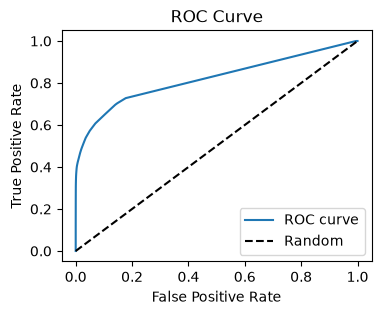

ROC AUC: 0.7710
Accuracy: 0.9702
Precision: 0.6743
Recall: 0.2598


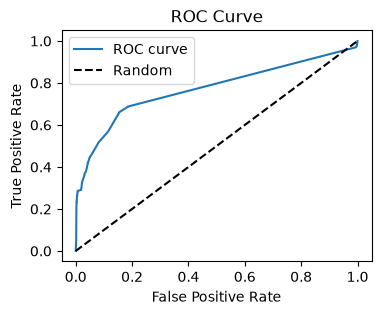

In [ ]:
def print_metrics(X, y, classifier):
    y_pred = classifier.predict(X)
    y_score = classifier.predict_proba(X)[:, 1]
    print(f"ROC AUC: {roc_auc_score(y, y_score):.4f}")
    print(f"Accuracy: {accuracy_score(y, y_pred):.4f}")
    print(f"Precision: {precision_score(y, y_pred):.4f}")
    print(f"Recall: {recall_score(y, y_pred):.4f}")

    fpr, tpr, thresholds = roc_curve(y, y_score)
    plt.figure(figsize=(4, 3))
    plt.plot(fpr, tpr, label='ROC curve')
    plt.plot([0, 1], [0, 1], 'k--', label='Random')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.show()

print_metrics(X_train, y_train, tree_classifier)
print_metrics(X_valid, y_valid, tree_classifier)

### Random Forest

In [29]:
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5
).fit(X_train, y_train)

/Users/eric/projects/kaggle/ieee-cis-fraud-detection/.venv/lib/python3.14/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


ROC AUC: 0.9434
Accuracy: 0.9798
Precision: 0.9834
Recall: 0.4323


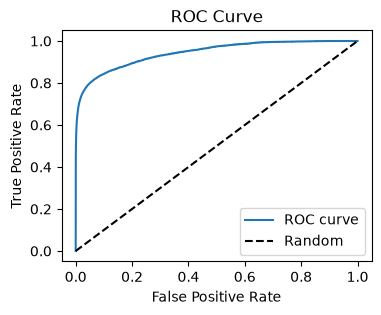

ROC AUC: 0.8811
Accuracy: 0.9735
Precision: 0.8409
Recall: 0.2822


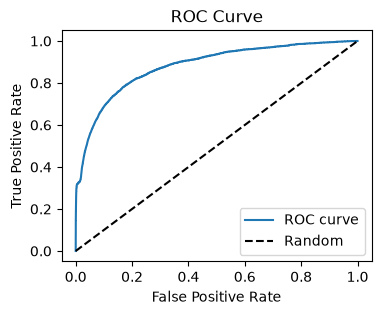

In [ ]:
print("Random Forest Performance on Training Set")
print_metrics(X_train, y_train, rf_classifier)

print("Random Forest Performance on Validation Set")
print_metrics(X_valid, y_valid, rf_classifier)

In [31]:
import xgboost as xgb

xgb_classifier = xgb.XGBClassifier(
    n_estimators=2000,
    learning_rate=0.02,
    early_stopping_rounds=200,
    max_depth=10,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc'
).fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=100)

[0]	validation_0-auc:0.83107
[100]	validation_0-auc:0.89605
[200]	validation_0-auc:0.90947
[300]	validation_0-auc:0.91546
[400]	validation_0-auc:0.91930
[500]	validation_0-auc:0.92168
[600]	validation_0-auc:0.92339
[700]	validation_0-auc:0.92443
[800]	validation_0-auc:0.92527
[900]	validation_0-auc:0.92568
[1000]	validation_0-auc:0.92595
[1100]	validation_0-auc:0.92631
[1200]	validation_0-auc:0.92646
[1300]	validation_0-auc:0.92623
[1350]	validation_0-auc:0.92620


ROC AUC: 0.9916
Accuracy: 0.9901
Precision: 0.9923
Recall: 0.7241


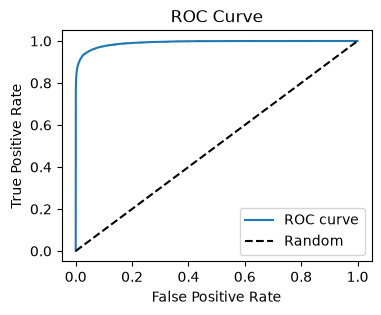

ROC AUC: 0.9265
Accuracy: 0.9758
Precision: 0.8231
Recall: 0.3777


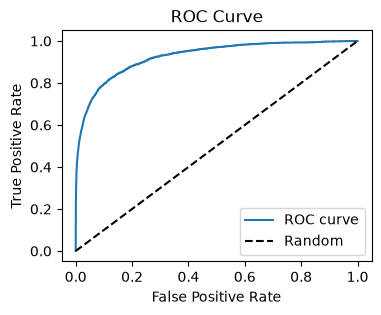

In [32]:
print_metrics(X_train, y_train, xgb_classifier)

print_metrics(X_valid, y_valid, xgb_classifier)

## Final model and submission

Now we refit on training + validation. The number of trees comes from early stopping on validation, scaled up because train + validation is 1/0.8 = 1.25x the data.

In [33]:
n_final = int(xgb_classifier.best_iteration * 1.2)
print('Best iteration:', xgb_classifier.best_iteration, '| final n_estimators:', n_final)

final_classifier = xgb.XGBClassifier(**{
    **xgb_classifier.get_params(),
    'n_estimators': n_final,
    'early_stopping_rounds': None,
}).fit(pd.concat([X_train, X_valid]), pd.concat([y_train, y_valid]))

Best iteration: 1150 | final n_estimators: 1380


In [34]:
sub = pd.read_csv(f'{path}/sample_submission.csv')
sub['isFraud'] = final_classifier.predict_proba(X_test.loc[sub['TransactionID']])[:, 1]
sub.to_csv('submission.csv', index=False)
sub.head()

,TransactionID,isFraud
0,3663549,0.002571
1,3663550,0.002923
2,3663551,0.000798
3,3663552,0.003844
4,3663553,0.000666


In [35]:
len(sub)

506691